<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Generating Synthetic Sales Data ---
Dataset successfully created. Shape: (730, 1)

--- Performing Feature Engineering ---
Train size: 614 days
Test/Evaluation size: 109 days

--- Training Random Forest Regressor ---

================ MODEL PERFORMANCE ================
Root Mean Squared Error (RMSE) : 21.22
Mean Absolute Error (MAE)       : 17.03
R-squared (R2 Score)            : 0.4347



/tmp/ipykernel_8062/2713195476.py:116: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x='Importance', y='Feature', data=feature_ranking, palette='viridis')


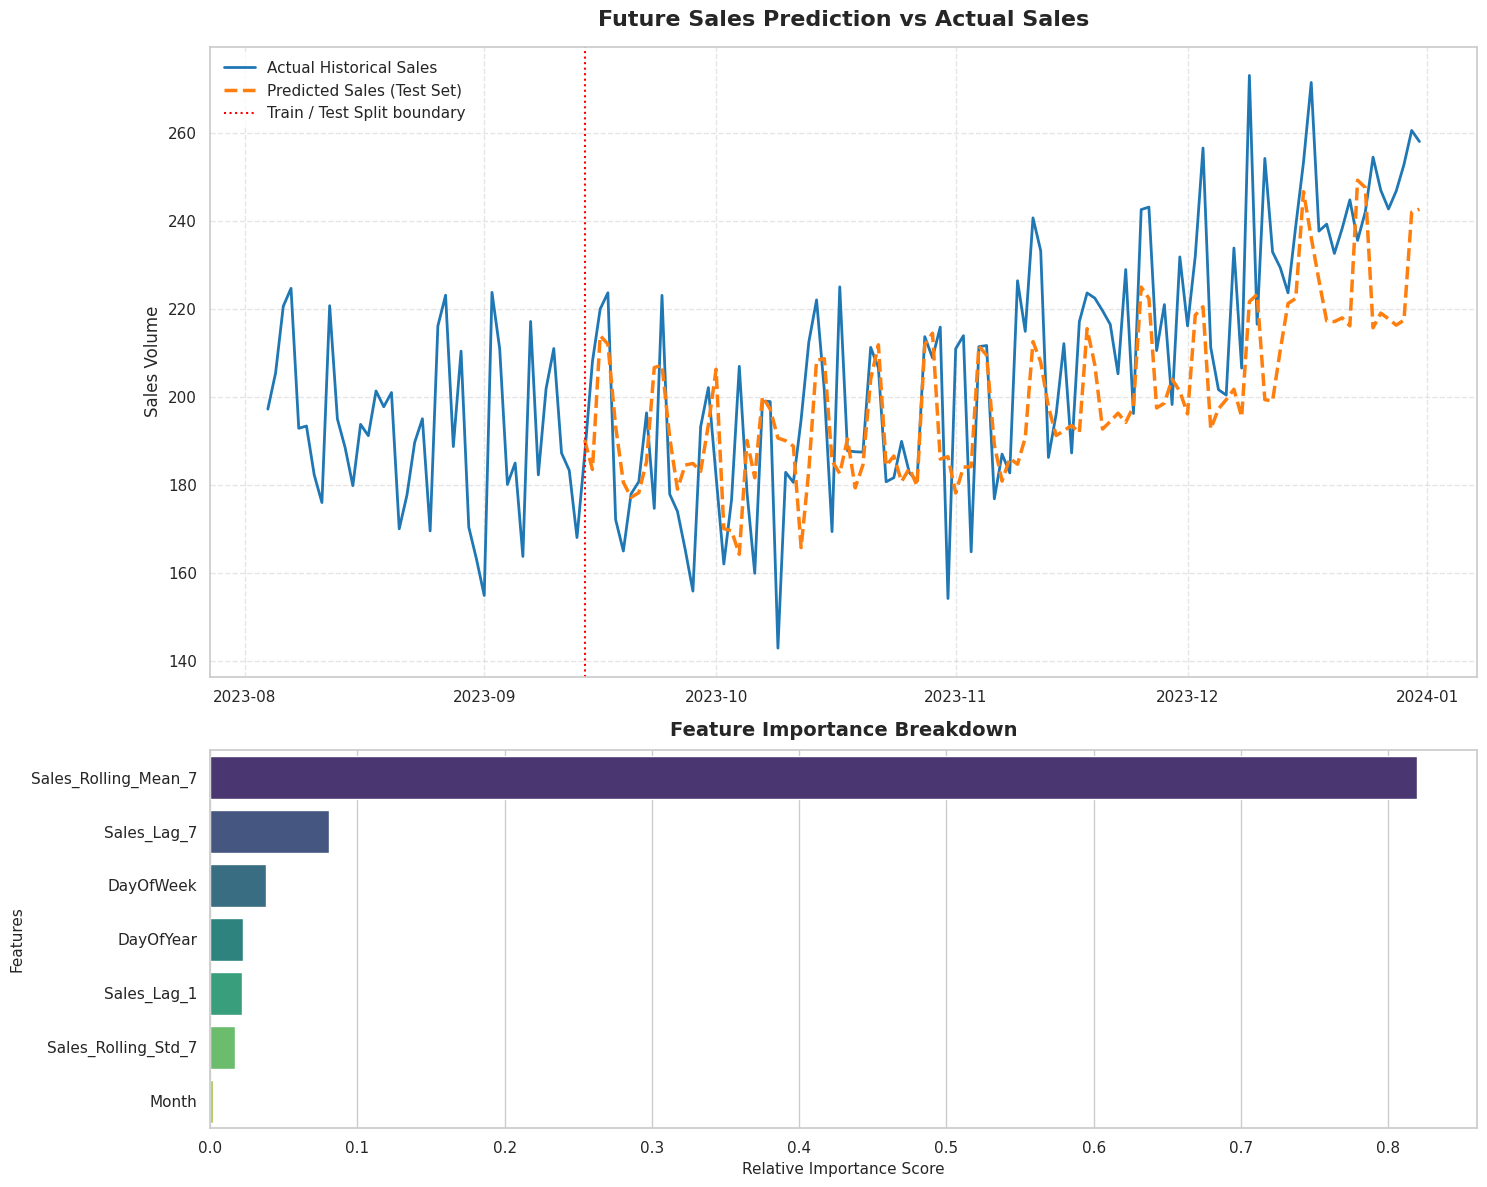

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set plot style for premium looking outputs
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

# ==========================================
# 1. DATA SIMULATION (Future Sales Context)
# ==========================================
print("--- Generating Synthetic Sales Data ---")
np.random.seed(42)
dates = pd.date_range(start="2022-01-01", end="2023-12-31", freq="D")
n_days = len(dates)

# Create a baseline trend + yearly seasonality (sine wave) + weekly seasonality + noise
trend = np.linspace(100, 250, n_days)
yearly_seasonality = 50 * np.sin(2 * np.pi * dates.dayofyear / 365.25)
weekly_seasonality = 20 * (dates.dayofweek >= 5)  # Higher sales on weekends
noise = np.random.normal(0, 15, n_days)

sales = trend + yearly_seasonality + weekly_seasonality + noise
sales = np.clip(sales, 10, None) # Ensure no negative sales

df = pd.DataFrame({'Date': dates, 'Sales': sales})
df.set_index('Date', inplace=True)
print(f"Dataset successfully created. Shape: {df.shape}\n")

# ==========================================
# 2. FEATURE ENGINEERING
# ==========================================
print("--- Performing Feature Engineering ---")
# Time features
df['DayOfWeek'] = df.index.dayofweek
df['Month'] = df.index.month
df['DayOfYear'] = df.index.dayofyear

# Lag features (using historical sales to predict future sales)
df['Sales_Lag_1'] = df['Sales'].shift(1)
df['Sales_Lag_7'] = df['Sales'].shift(7)

# Rolling statistics
df['Sales_Rolling_Mean_7'] = df['Sales'].shift(1).rolling(window=7).mean()
df['Sales_Rolling_Std_7'] = df['Sales'].shift(1).rolling(window=7).std()

# Drop rows with NaN values resulting from lag/rolling shifts
df.dropna(inplace=True)

# Define Features & Target
features = ['DayOfWeek', 'Month', 'DayOfYear', 'Sales_Lag_1', 'Sales_Lag_7', 'Sales_Rolling_Mean_7', 'Sales_Rolling_Std_7']
X = df[features]
y = df['Sales']

# ==========================================
# 3. TRAIN-TEST SPLIT (Temporal Split)
# ==========================================
# We split chronologically because this is a time-series forecasting task
split_idx = int(len(df) * 0.85)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train size: {X_train.shape[0]} days")
print(f"Test/Evaluation size: {X_test.shape[0]} days\n")

# ==========================================
# 4. MODEL TRAINING & PREDICTION
# ==========================================
print("--- Training Random Forest Regressor ---")
model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# ==========================================
# 5. METRICS & PERFORMANCE EVALUATION
# ==========================================
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n================ MODEL PERFORMANCE ================")
print(f"Root Mean Squared Error (RMSE) : {rmse:.2f}")
print(f"Mean Absolute Error (MAE)       : {mae:.2f}")
print(f"R-squared (R2 Score)            : {r2:.4f}")
print("====================================================\n")

# ==========================================
# 6. PRESENTABLE OUTPUT VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(15, 12), gridspec_kw={'height_ratios': [2, 1.2]})

# Plot 1: Actual vs Predicted Future Sales
axes[0].plot(df.index[-150:], y.iloc[-150:], label='Actual Historical Sales', color='#1f77b4', linewidth=2)
axes[0].plot(y_test.index, y_pred, label='Predicted Sales (Test Set)', color='#ff7f0e', linestyle='--', linewidth=2.5)
axes[0].axvline(x=y_test.index[0], color='red', linestyle=':', label='Train / Test Split boundary')
axes[0].set_title('Future Sales Prediction vs Actual Sales', fontsize=16, fontweight='bold', pad=15)
axes[0].set_ylabel('Sales Volume', fontsize=12)
axes[0].legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Feature Importance
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
feature_ranking = pd.DataFrame({
    'Feature': [features[i] for i in indices],
    'Importance': importances[indices]
})

sns.barplot(ax=axes[1], x='Importance', y='Feature', data=feature_ranking, palette='viridis')
axes[1].set_title('Feature Importance Breakdown', fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel('Relative Importance Score', fontsize=11)
axes[1].set_ylabel('Features', fontsize=11)

plt.tight_layout()
plt.show()
